In [6]:
# Compute RSI
def compute_rsi(series, period=14):
    delta = series.diff(1)
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.rolling(window=period).mean()
    avg_loss = loss.rolling(window=period).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Compute MACD
def compute_macd(series, short_period=12, long_period=26, signal_period=9):
    short_ema = series.ewm(span=short_period, adjust=False).mean()
    long_ema = series.ewm(span=long_period, adjust=False).mean()
    macd = short_ema - long_ema
    macd_signal = macd.ewm(span=signal_period, adjust=False).mean()
    return macd, macd_signal

c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
[*********************100%%**********************]  1 of 1 completed


Historical data range: 2024-06-24 09:30:00 to 2024-06-28 15:30:00
Number of data points: 65


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━

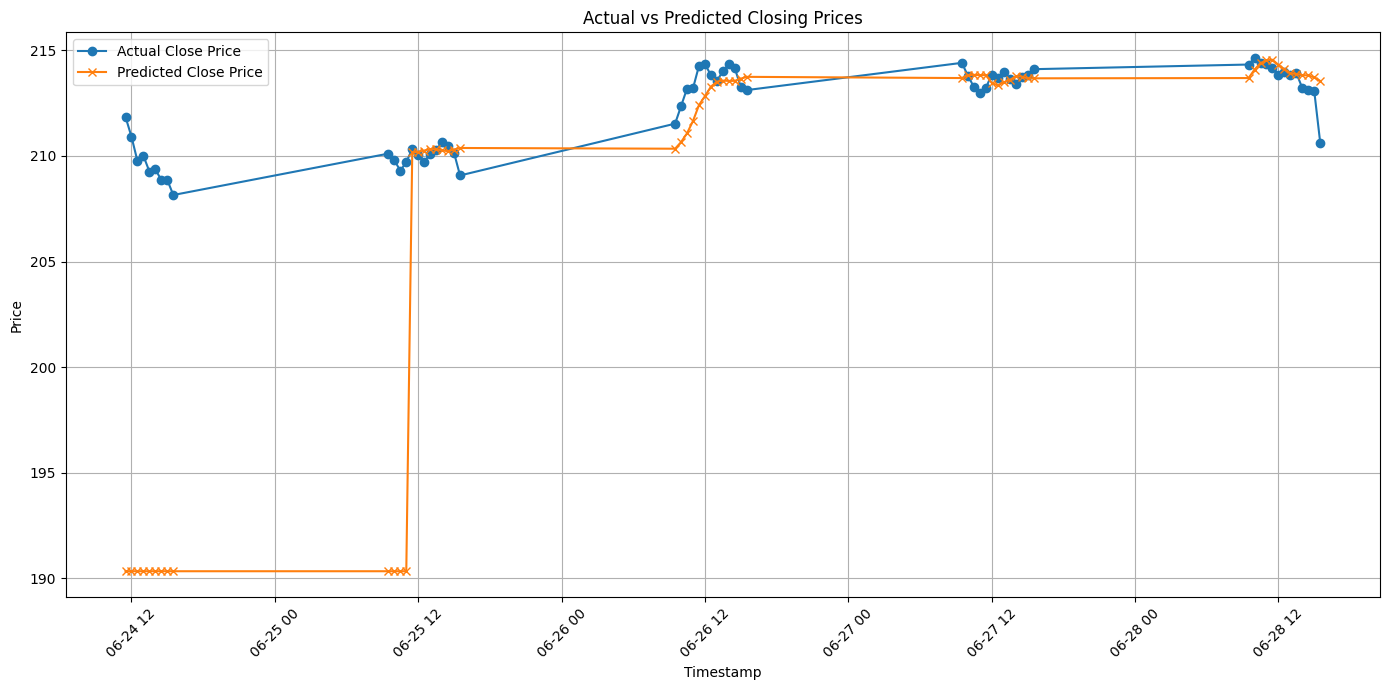

(10000,
 10026.606750488281,
 [('buy', 47.0, 210.03140258789062),
  ('buy', 0.0, 209.7165985107422),
  ('buy', 0.0, 210.11500549316406),
  ('buy', 0.0, 210.27999877929688),
  ('sell', 47.0, 210.66000366210938),
  ('buy', 47.0, 210.14010620117188),
  ('buy', 0.0, 209.0760040283203),
  ('sell', 47.0, 211.52999877929688),
  ('buy', 47.0, 213.26199340820312),
  ('buy', 0.0, 213.1199951171875),
  ('sell', 47.0, 214.41000366210938),
  ('buy', 47.0, 213.80999755859375),
  ('buy', 0.0, 213.27999877929688),
  ('buy', 0.0, 212.9705047607422),
  ('buy', 0.0, 213.2050018310547),
  ('sell', 47.0, 213.85499572753906),
  ('buy', 47.0, 213.4199981689453),
  ('buy', 0.0, 213.74000549316406),
  ('sell', 47.0, 213.8289031982422),
  ('buy', 47.0, 214.3800048828125),
  ('buy', 0.0, 214.33999633789062),
  ('buy', 0.0, 214.17999267578125),
  ('buy', 0.0, 213.83999633789062),
  ('buy', 0.0, 213.9550018310547),
  ('buy', 0.0, 213.83009338378906),
  ('sell', 47.0, 213.9257049560547),
  ('buy', 47.0, 213.2100067

In [26]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

SEQ_LENGTH = 4

# Function to fetch data from Yahoo Finance
def fetch_data(stock_code, interval='30m', start_date='2023-06-23', end_date='2023-06-30'):
    data = yf.download(stock_code, interval=interval, start=start_date, end=end_date)
    data['RSI'] = compute_rsi(data['Close'])
    data['MACD'], data['MACD_Signal'] = compute_macd(data['Close'])
    return data

# Function to compute RSI (example implementation)
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Function to compute MACD (example implementation)
def compute_macd(data, slow=26, fast=12, signal=9):
    exp1 = data.ewm(span=fast, adjust=False).mean()
    exp2 = data.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Function to preprocess data for prediction
def preprocess_data_for_prediction(data, scaler):
    # Add missing columns with default values
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    for col in required_columns:
        if col not in data.columns:
            data[col] = 0
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

# Function to predict the next closing price
def predict_next_closing_price(model, scaler, data_for_prediction):
    # Preprocess data for prediction
    data_for_prediction = preprocess_data_for_prediction(data_for_prediction, scaler)
    data_for_prediction = np.array([data_for_prediction])  # Reshape to 3D array
    
    # Predict with the model
    predicted_price_scaled = model.predict(data_for_prediction)
    
    # Construct a dummy array to mimic the original feature structure
    features_dummy = np.zeros((predicted_price_scaled.shape[0], 7))
    features_dummy[:, 3] = predicted_price_scaled[:, 0]  # Assuming 'Close' is the 4th column
    
    # Inverse transform to get the actual predicted price
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    
    # Extract the scalar value from the array
    predicted_price = predicted_price[0]
    
    return predicted_price

# Function to execute trading strategy
def execute_trading(model, scaler, historical_data):
    initial_cash = 10000  # Example starting cash
    cash = initial_cash
    shares = 0
    transactions = []

    if historical_data.empty or len(historical_data) < SEQ_LENGTH:
        raise ValueError("Not enough data to perform backtesting.")

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            current_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            
            # Example trading logic: buy if predicted price is higher than current price
            if predicted_price > current_price and cash > 0:
                shares_to_buy = cash // current_price
                cash -= shares_to_buy * current_price
                shares += shares_to_buy
                transactions.append(('buy', shares_to_buy, current_price))
            
            # Sell if predicted price is lower than current price
            elif predicted_price < current_price and shares > 0:
                cash += shares * current_price
                transactions.append(('sell', shares, current_price))
                shares = 0
    
    final_portfolio_value = cash + shares * historical_data['Close'].iloc[-1]
    return initial_cash, final_portfolio_value, transactions

def backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date):
    model = load_model(model_path)
    scaler = joblib.load(scaler_path)
    
    # Fetch historical data for the backtest period
    historical_data = fetch_data(stock_code, interval='30m', start_date=start_date, end_date=end_date)
    
    # Debug print to check the data range
    print(f"Historical data range: {historical_data.index.min()} to {historical_data.index.max()}")
    print(f"Number of data points: {len(historical_data)}")
    
    # Execute trading strategy
    initial_cash, final_portfolio_value, transactions = execute_trading(model, scaler, historical_data)
    
    # Calculate returns
    returns = (final_portfolio_value - initial_cash) / initial_cash
    
    # Print results
    print(f"Initial Cash: {initial_cash}")
    print(f"Final Portfolio Value: {final_portfolio_value}")
    print(f"Returns: {returns * 100:.2f}%")
    print(f"Transactions: {transactions}")
    
    # Prepare data for plotting
    predicted_prices = []
    actual_prices = []
    timestamps = []
    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            actual_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            timestamp = historical_data.index[i + SEQ_LENGTH]
            
            predicted_prices.append(predicted_price)
            actual_prices.append(actual_price)
            timestamps.append(timestamp)
    
    # Plotting predicted vs actual prices
    plt.figure(figsize=(14, 7))
    plt.plot(timestamps, actual_prices, label='Actual Close Price', marker='o')
    plt.plot(timestamps, predicted_prices, label='Predicted Close Price', marker='x')
    plt.title('Actual vs Predicted Closing Prices')
    plt.xlabel('Timestamp')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return initial_cash, final_portfolio_value, transactions

# Fetch data for the backtesting period
stock_code = 'AAPL'
start_date = '2024-06-23'
end_date = '2024-06-30'

# Perform backtesting
backtest_trading_strategy(stock_code, 'model.keras', 'scaler.pkl', start_date, end_date)


c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:239: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  quotes2 = quotes.resample('30T')
[*********************100%%**********************]  1 of 1 completed
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0


Historical data range: 2024-06-24 09:30:00 to 2024-06-28 15:30:00
Number of data points: 65
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

... (6 outputs left out)

C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0
C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

C:\Users\Asad\AppData\Local\Temp\ipykernel_16772\3565623691.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = 0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━

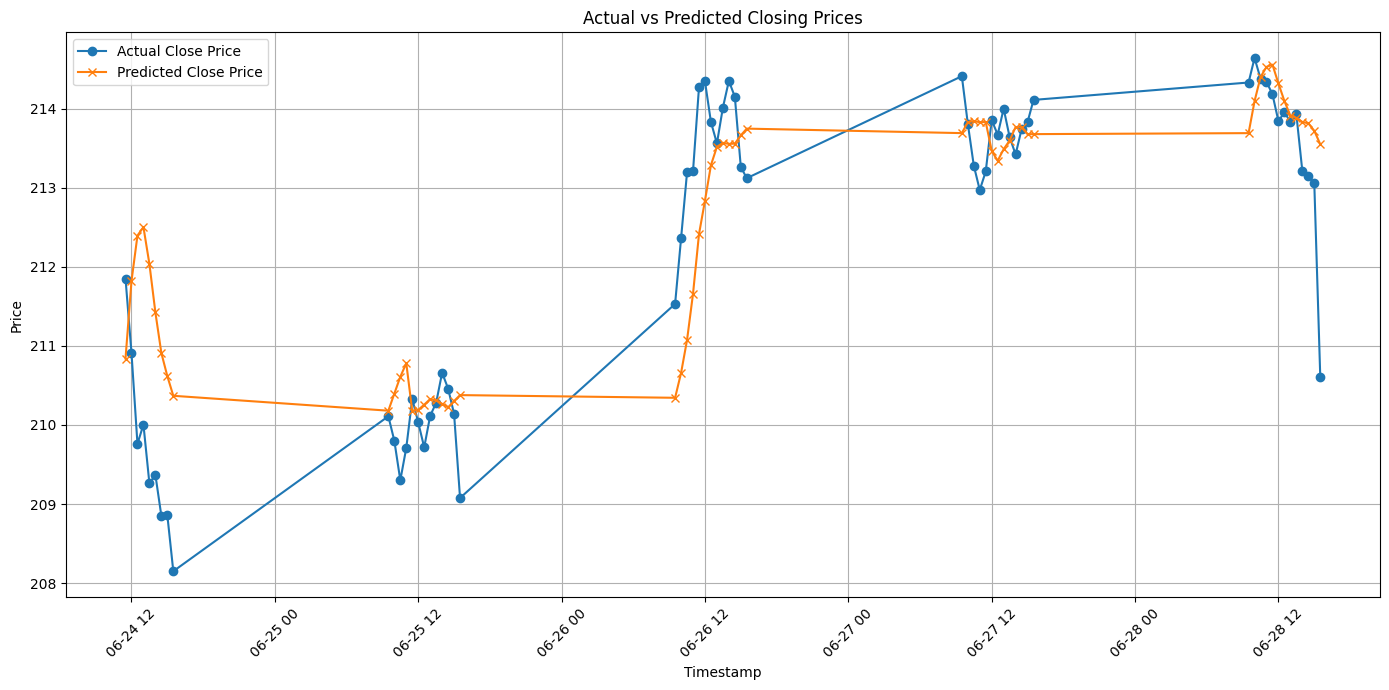

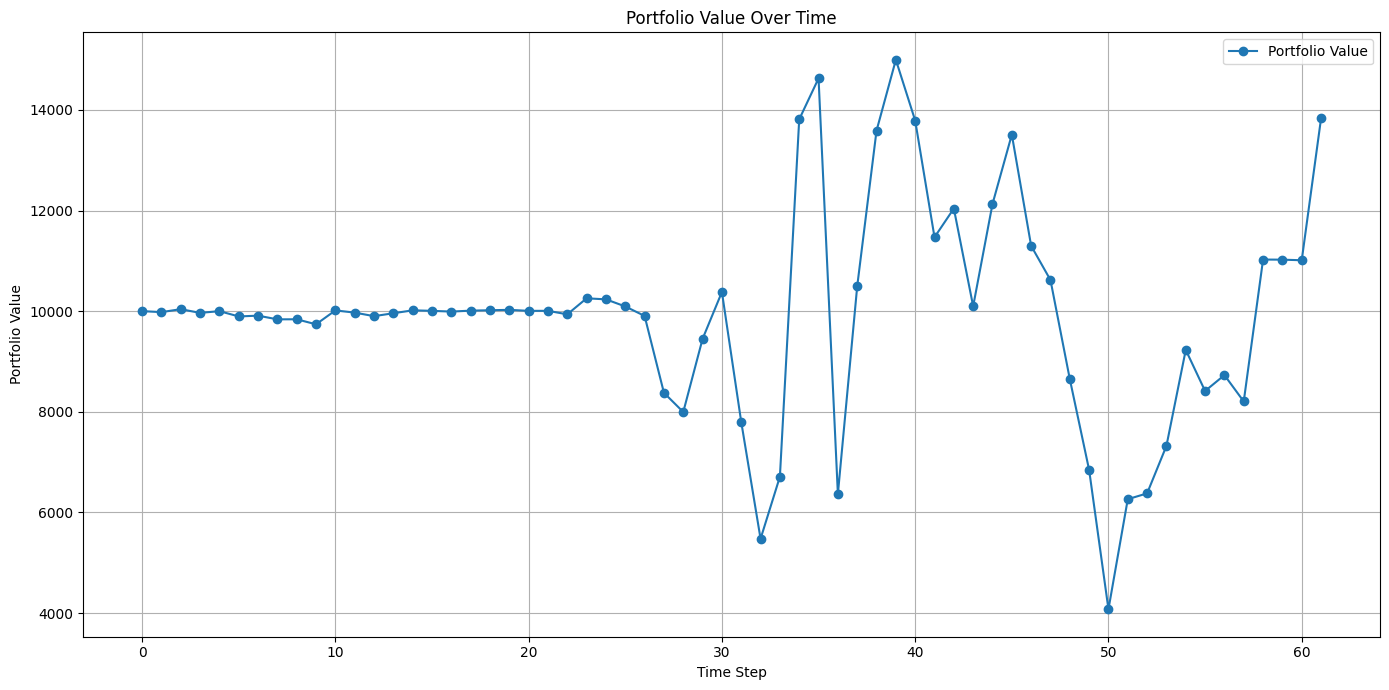

(10000,
 13829.91935894778,
 [('short_sell', 94.0, 211.8498992919922),
  ('buy', 141.0, 210.91000366210938),
  ('cover_short', 94.0, 209.75999450683594),
  ('sell', 141.0, 210.3300018310547),
  ('buy', 47.0, 210.03140258789062),
  ('sell', 47.0, 210.66000366210938),
  ('short_sell', 95.0, 210.4600067138672),
  ('buy', 142.0, 210.14010620117188),
  ('cover_short', 95.0, 209.0760040283203),
  ('sell', 142.0, 211.52999877929688),
  ('short_sell', 96.0, 212.36000061035156),
  ('short_sell', 286.0, 213.19500732421875),
  ('short_sell', 857.0, 213.2100067138672),
  ('short_sell', 1000, 214.27000427246094),
  ('short_sell', 1000, 214.34500122070312),
  ('short_sell', 1000, 213.8300018310547),
  ('short_sell', 1000, 213.55999755859375),
  ('short_sell', 1000, 214.01220703125),
  ('short_sell', 1000, 214.35000610351562),
  ('short_sell', 1000, 214.14999389648438),
  ('buy', 1000, 213.26199340820312),
  ('buy', 1000, 213.1199951171875),
  ('sell', 1000, 214.41000366210938),
  ('buy', 1000, 213.8

In [31]:
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

SEQ_LENGTH = 4
MAX_POSITION_SIZE = 1000  # Maximum number of shares to buy/sell at once
TRANSACTION_COST = 0.001  # 0.1% transaction cost
MARGIN_REQUIREMENT = 0.5  # 50% margin requirement for short selling

# Function to fetch data from Yahoo Finance
def fetch_data(stock_code, interval='30m', start_date='2023-06-23', end_date='2023-06-30'):
    data = yf.download(stock_code, interval=interval, start=start_date, end=end_date)
    data['RSI'] = compute_rsi(data['Close'])
    data['MACD'], data['MACD_Signal'] = compute_macd(data['Close'])
    return data

# Function to compute RSI
def compute_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Function to compute MACD
def compute_macd(data, slow=26, fast=12, signal=9):
    exp1 = data.ewm(span=fast, adjust=False).mean()
    exp2 = data.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Function to preprocess data for prediction
def preprocess_data_for_prediction(data, scaler):
    # Add missing columns with default values
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    for col in required_columns:
        if (col not in data.columns) or (data[col].isnull().any()):
            data[col] = 0
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

# Function to predict the next closing price
def predict_next_closing_price(model, scaler, data_for_prediction):
    # Preprocess data for prediction
    data_for_prediction = preprocess_data_for_prediction(data_for_prediction, scaler)
    data_for_prediction = np.array([data_for_prediction])  # Reshape to 3D array
    
    # Predict with the model
    predicted_price_scaled = model.predict(data_for_prediction)
    
    # Construct a dummy array to mimic the original feature structure
    features_dummy = np.zeros((predicted_price_scaled.shape[0], 7))
    features_dummy[:, 3] = predicted_price_scaled[:, 0]  # Assuming 'Close' is the 4th column
    
    # Inverse transform to get the actual predicted price
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    
    # Extract the scalar value from the array
    predicted_price = predicted_price[0]
    
    return predicted_price

# Function to execute trading strategy
def execute_trading(model, scaler, historical_data):
    initial_cash = 10000  # Example starting cash
    cash = initial_cash
    shares = 0
    short_shares = 0
    transactions = []
    portfolio_value = [initial_cash]

    if historical_data.empty or len(historical_data) < SEQ_LENGTH:
        raise ValueError("Not enough data to perform backtesting.")

    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            current_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            
            # Trading logic
            if predicted_price > current_price and cash > current_price * (1 + TRANSACTION_COST):
                shares_to_buy = min(cash // (current_price * (1 + TRANSACTION_COST)), MAX_POSITION_SIZE)
                if shares_to_buy > 0:
                    cash -= shares_to_buy * current_price * (1 + TRANSACTION_COST)
                    shares += shares_to_buy
                    transactions.append(('buy', shares_to_buy, current_price))
            
            elif predicted_price < current_price and shares > 0:
                shares_to_sell = min(shares, MAX_POSITION_SIZE)
                if shares_to_sell > 0:
                    cash += shares_to_sell * current_price * (1 - TRANSACTION_COST)
                    shares -= shares_to_sell
                    transactions.append(('sell', shares_to_sell, current_price))
            
            # Short selling logic
            elif predicted_price < current_price and cash > current_price * (1 + TRANSACTION_COST) * MARGIN_REQUIREMENT:
                shares_to_short = min(cash // (current_price * (1 + TRANSACTION_COST) * MARGIN_REQUIREMENT), MAX_POSITION_SIZE)
                if shares_to_short > 0:
                    cash += shares_to_short * current_price * (1 - TRANSACTION_COST)
                    short_shares += shares_to_short
                    transactions.append(('short_sell', shares_to_short, current_price))
            
            elif predicted_price > current_price and short_shares > 0:
                shares_to_cover = min(short_shares, MAX_POSITION_SIZE)
                if shares_to_cover > 0:
                    cash -= shares_to_cover * current_price * (1 + TRANSACTION_COST)
                    short_shares -= shares_to_cover
                    transactions.append(('cover_short', shares_to_cover, current_price))
        
        # Calculate current portfolio value and append to the list
        current_portfolio_value = cash + shares * current_price - short_shares * current_price
        portfolio_value.append(current_portfolio_value)

    final_portfolio_value = cash + shares * historical_data['Close'].iloc[-1] - short_shares * historical_data['Close'].iloc[-1]
    return initial_cash, final_portfolio_value, transactions, portfolio_value

# Function to backtest trading strategy
def backtest_trading_strategy(stock_code, model_path, scaler_path, start_date, end_date):
    model = load_model(model_path)
    scaler = joblib.load(scaler_path)
    
    # Fetch historical data for the backtest period
    historical_data = fetch_data(stock_code, interval='30m', start_date=start_date, end_date=end_date)
    
    # Debug print to check the data range
    print(f"Historical data range: {historical_data.index.min()} to {historical_data.index.max()}")
    print(f"Number of data points: {len(historical_data)}")
    
    # Execute trading strategy
    initial_cash, final_portfolio_value, transactions, portfolio_value = execute_trading(model, scaler, historical_data)
    
    # Calculate returns
    returns = (final_portfolio_value - initial_cash) / initial_cash
    
    # Print results
    print(f"Initial Cash: {initial_cash}")
    print(f"Final Portfolio Value: {final_portfolio_value}")
    print(f"Returns: {returns * 100:.2f}%")
    print(f"Transactions: {transactions}")
    
    # Prepare data for plotting
    predicted_prices = []
    actual_prices = []
    timestamps = []
    for i in range(len(historical_data) - SEQ_LENGTH):
        current_data = historical_data.iloc[i:i+SEQ_LENGTH]
        data_for_prediction = current_data[['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']]
        
        if len(data_for_prediction) == SEQ_LENGTH:
            predicted_price = predict_next_closing_price(model, scaler, data_for_prediction)
            actual_price = historical_data['Close'].iloc[i + SEQ_LENGTH]
            timestamp = historical_data.index[i + SEQ_LENGTH]
            
            predicted_prices.append(predicted_price)
            actual_prices.append(actual_price)
            timestamps.append(timestamp)
    
    # Plotting predicted vs actual prices
    plt.figure(figsize=(14, 7))
    plt.plot(timestamps, actual_prices, label='Actual Close Price', marker='o')
    plt.plot(timestamps, predicted_prices, label='Predicted Close Price', marker='x')
    plt.title('Actual vs Predicted Closing Prices')
    plt.xlabel('Timestamp')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plotting portfolio value over time
    plt.figure(figsize=(14, 7))
    plt.plot(portfolio_value, label='Portfolio Value', marker='o')
    plt.title('Portfolio Value Over Time')
    plt.xlabel('Time Step')
    plt.ylabel('Portfolio Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return initial_cash, final_portfolio_value, transactions

# Fetch data for the backtesting period
stock_code = 'AAPL'
start_date = '2024-06-23'
end_date = '2024-06-30'

# Perform backtesting
backtest_trading_strategy(stock_code, 'model.keras', 'scaler.pkl', start_date, end_date)

In [2]:
import alpaca_trade_api as tradeapi
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import joblib
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import datetime
import time
import logging

# Replace with your API key details
API_KEY = 'PKS83XYYEBQDAQUMC11P'
API_SECRET = 'phV8PZYN9xZsubzhH3xBAjaqKAC4hW54VwdXKHq6'
APCA_API_BASE_URL = 'https://paper-api.alpaca.markets'  # Paper trading base URL

# Initialize API connection
api = tradeapi.REST(API_KEY, API_SECRET, APCA_API_BASE_URL, api_version='v2')

# Setup logging
logging.basicConfig(filename='trading_log.log', level=logging.INFO,
                    format='%(asctime)s - %(levelname)s - %(message)s')

# Load model and scaler
model = load_model('model.keras')
scaler = joblib.load('scaler.pkl')

def compute_rsi(prices, window=14):
    delta = prices.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def compute_macd(prices, slow=26, fast=12, signal=9):
    exp1 = prices.ewm(span=fast, adjust=False).mean()
    exp2 = prices.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

def fetch_data(symbol, interval='30Min', start='2023-06-23T09:30:00-04:00', end='2023-06-30T16:00:00-04:00'):
    df = api.get_bars(symbol, interval, start=start, end=end).df
    df = df[['open', 'high', 'low', 'close', 'volume']]
    df.columns = ['Open', 'High', 'Low', 'Close', 'Volume']

    # Calculate RSI and MACD
    df['RSI'] = compute_rsi(df['Close'])
    macd, macd_signal = compute_macd(df['Close'])
    df['MACD'] = macd
    df['MACD_Signal'] = macd_signal

    return df

def preprocess_data_for_prediction(data, scaler):
    required_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    data_scaled = scaler.transform(data[required_columns])
    return data_scaled

def predict_next_closing_price(data_for_prediction):
    data_for_prediction = np.array([data_for_prediction[-SEQ_LENGTH:]])  # Reshape for the model
    predicted_price_scaled = model.predict(data_for_prediction)
    features_dummy = np.zeros((1, 7))
    features_dummy[:, 3] = predicted_price_scaled[0, 0]  # Assuming 'Close' is the 4th column
    predicted_price = scaler.inverse_transform(features_dummy)[:, 3]
    return predicted_price[0]

def execute_trade(symbol, prediction, current_price):
    if prediction > current_price * (1 + TRANSACTION_COST):
        qty_to_trade = min(int(10000 / current_price), MAX_POSITION_SIZE)
        print(f"Buying {qty_to_trade} shares at {current_price}")
        api.submit_order(symbol=symbol, qty=qty_to_trade, side='buy', type='market', time_in_force='gtc')
        logging.info(f"Bought {qty_to_trade} shares of {symbol} at {current_price}")
    elif prediction < current_price * (1 - TRANSACTION_COST):
        qty_to_trade = min(int(10000 / current_price), MAX_POSITION_SIZE)
        print(f"Selling {qty_to_trade} shares at {current_price}")
        api.submit_order(symbol=symbol, qty=qty_to_trade, side='sell', type='market', time_in_force='gtc')
        logging.info(f"Sold {qty_to_trade} shares of {symbol} at {current_price}")

def align_to_interval():
    now = datetime.datetime.now()
    wait_time = 1800 - (now.minute * 60 + now.second) % 1800  # Wait time until the next half-hour mark
    time.sleep(wait_time)

try:
    while True:
        align_to_interval()  # Align execution to 30-minute intervals
        current_time = datetime.datetime.now()
        start_time = current_time - datetime.timedelta(minutes=30)
        
        # Fetch and process the data
        data = fetch_data('AAPL', start=start_time.isoformat(), end=current_time.isoformat())
        preprocessed_data = preprocess_data_for_prediction(data, scaler)
        
        # Predict and execute trades
        prediction = predict_next_closing_price(preprocessed_data)
        execute_trade('AAPL', prediction, data['Close'].iloc[-1])

except Exception as e:
    print(f"An error occurred: {e}")
    # Consider logging the error and potentially alerting
